# DATA UNDERSTANDING

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime


from pathlib import Path

BASE = Path.cwd()

# Support running from the project root or notebooks/ folder
if not (BASE / "data").is_dir():
    if (BASE.parent / "data").is_dir():
        BASE = BASE.parent
    else:
        raise FileNotFoundError(
            "Project data folder not found. "
            "Run this notebook from the project root or notebooks folder."
        )

RAW = BASE / "data" / "raw"
PROC = BASE / "data" / "processed"
DB = BASE / "data" / "logistics.db"

# Create only the directory needed for processed datasets
PROC.mkdir(parents=True, exist_ok=True)

print("Project root:", BASE)
print("Raw data:", RAW)
print("Processed data:", PROC)

Project root: d:\Athar\LogiTech_Logistics_Analysis
Raw data: d:\Athar\LogiTech_Logistics_Analysis\data\raw
Processed data: d:\Athar\LogiTech_Logistics_Analysis\data\processed


In [2]:
shipment_fp = RAW / "ShipmentDelivery.xlsx"
inventory_fp = RAW / "InventoryStockMovement.xlsx"
warehouse_fp = RAW / "WarehouseOperations.csv"

shipment = pd.read_excel(shipment_fp)
inventory = pd.read_excel(inventory_fp)
warehouse = pd.read_csv(warehouse_fp)

print("Shapes -> shipment:", shipment.shape, ", inventory:", inventory.shape, ", warehouse:", warehouse.shape)
display(shipment.head(3))
display(inventory.head(3))
display(warehouse.head(3))

print("\nShipment columns:\n", list(shipment.columns))

Shapes -> shipment: (209402, 14) , inventory: (2036, 9) , warehouse: (19, 9)


,Shipment_ID,Customer,Warehouse_ID,Destination_Region,Dispatch_Date,Delivery_Date,Delivery_Time_Days,Weight,Carrier_Name,Shipment_Status,Delivery_Mode,Shipment_Cost,Delivery_Accuracy_Flag,Damage_Flag
0,S000001,V55555_53,PLANT16,PORT09,2024-12-15,2024-12-18,3,14.30,V44_3,Delivered,NaN,NaN,1,0
1,S000002,V55555_53,PLANT16,PORT09,2023-03-28,2023-04-01,4,87.94,V44_3,Delivered,NaN,NaN,1,0
2,S000003,V55555_53,PLANT16,PORT09,2024-01-19,2024-01-24,5,61.20,V44_3,Delivered,NaN,NaN,1,1


,Product_ID,Warehouse_ID,Category,Stock_On_Hand,Reorder_Level,Reorder_Flag,Avg_Lead_Time_Days,Stockout_Days,Carrying_Cost_Per_Unit
0,1698815,PLANT15,Misc,149,10,0,5,0,0.28
1,1664419,PLANT17,Misc,6,10,1,5,1,0.09
2,1664426,PLANT17,Misc,6,10,1,5,1,0.09


,Warehouse_ID,Warehouse_Capacity_Units,Current_Inventory_Units,Inventory_Turnover_Ratio,Order_Fulfilment_Rate,Avg_Pick_Pack_Time_Min,Warehouse_Utilization_%,Labour_Hours_Per_Day,Operational_Cost_Per_Day
0,PLANT15,246,149,2.81904,NaN,22,60.57,3,42.17
1,PLANT17,179,112,2.81904,NaN,24,62.57,3,9.61
2,PLANT18,2488,2041,2.81904,NaN,24,82.03,4,831.20



Shipment columns:
 ['Shipment_ID', 'Customer', 'Warehouse_ID', 'Destination_Region', 'Dispatch_Date', 'Delivery_Date', 'Delivery_Time_Days', 'Weight', 'Carrier_Name', 'Shipment_Status', 'Delivery_Mode', 'Shipment_Cost', 'Delivery_Accuracy_Flag', 'Damage_Flag']


In [3]:
def basic_report(df, name):
    print(f"\n=== {name} ===")
    print("Shape:", df.shape)
    print("\nMissing Values:")
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    print(missing)

basic_report(shipment, "shipment")
basic_report(inventory, "inventory")
basic_report(warehouse, "warehouse")


=== shipment ===
Shape: (209402, 14)

Missing Values:
Delivery_Mode    854
Shipment_Cost    854
dtype: int64

=== inventory ===
Shape: (2036, 9)

Missing Values:
Series([], dtype: int64)

=== warehouse ===
Shape: (19, 9)

Missing Values:
Order_Fulfilment_Rate    12
dtype: int64


In [4]:
def parse_dates_for_shipment(df):
    
    df.columns = df.columns.str.strip()
    
    df['Dispatch_Date'] = pd.to_datetime(df['Dispatch_Date'], errors='coerce')
    df['Delivery_Date'] = pd.to_datetime(df['Delivery_Date'], errors='coerce')
    
    df['Delivery_Time_Days'] = (df['Delivery_Date'] - df['Dispatch_Date']).dt.days
    
    return df

shipment = parse_dates_for_shipment(shipment)
display(shipment[['Dispatch_Date','Delivery_Date','Delivery_Time_Days']].head(10))
print("Derived Delivery_Time_Days - missing count:", shipment['Delivery_Time_Days'].isna().sum())

,Dispatch_Date,Delivery_Date,Delivery_Time_Days
0,2024-12-15,2024-12-18,3
1,2023-03-28,2023-04-01,4
2,2024-01-19,2024-01-24,5
3,2023-10-21,2023-10-26,5
4,2024-07-21,2024-07-24,3
5,2024-05-27,2024-06-01,5
6,2023-12-22,2023-12-25,3
7,2023-08-09,2023-08-11,2
8,2024-11-21,2024-11-23,2
9,2024-09-11,2024-09-16,5


Derived Delivery_Time_Days - missing count: 0


In [5]:
def flag_negatives(df, df_name):
    negatives = {}
    numeric_cols = df.select_dtypes(include=['int64','float64']).columns.tolist()
    for c in numeric_cols:
        neg_count = int((df[c] < 0).sum())
        if neg_count > 0:
            negatives[c] = neg_count
            df[c + "_orig"] = df[c]
            df[c + "_neg_flag"] = df[c] < 0
            df.loc[df[c] < 0, c] = np.nan
    print(f"{df_name} negatives flagged:", negatives)
    return df, negatives

shipment, neg_ship = flag_negatives(shipment, "shipment")
inventory, neg_inv = flag_negatives(inventory, "inventory")

shipment negatives flagged: {}
inventory negatives flagged: {}


In [6]:
before = shipment.shape[0]
shipment = shipment.drop_duplicates().reset_index(drop=True)
after = shipment.shape[0]
duplicates_removed = int(before - after)
print("Exact duplicates removed (shipment):", duplicates_removed)

if 'Shipment_ID' in shipment.columns and 'Delivery_Date' in shipment.columns:
    dup_count = shipment.duplicated(subset=['Shipment_ID'], keep=False).sum()
    print("Rows with duplicated Shipment_ID:", dup_count)
    shipment = shipment.sort_values('Delivery_Date').drop_duplicates(subset=['Shipment_ID'], keep='last').reset_index(drop=True)

mask_bad = shipment['Dispatch_Date'].notna() & shipment['Delivery_Date'].notna() & (shipment['Delivery_Date'] < shipment['Dispatch_Date'])
print("Rows where Delivery < Dispatch:", mask_bad.sum())
if mask_bad.sum() > 0:
    diffs = (shipment.loc[mask_bad, 'Dispatch_Date'] - shipment.loc[mask_bad, 'Delivery_Date']).dt.days.abs()
    idx_swap = diffs[diffs <= 7].index
    idx_null = diffs[diffs > 7].index
    shipment.loc[idx_swap, ['Dispatch_Date','Delivery_Date']] = shipment.loc[idx_swap, ['Delivery_Date','Dispatch_Date']].values
    shipment.loc[idx_null, 'Delivery_Date'] = pd.NaT

    shipment['Delivery_Date_fixed_flag'] = False
    shipment.loc[idx_swap, 'Delivery_Date_fixed_flag'] = True

shipment['Delivery_Time_Days'] = (shipment['Delivery_Date'] - shipment['Dispatch_Date']).dt.days
print("After fixes, Delivery_Time_Days missing:", shipment['Delivery_Time_Days'].isna().sum())

Exact duplicates removed (shipment): 72850
Rows with duplicated Shipment_ID: 135698
Rows where Delivery < Dispatch: 0
After fixes, Delivery_Time_Days missing: 0


In [7]:
proc_shipment = PROC / "shipment_cleaned.csv"
proc_inventory = PROC / "inventory_cleaned.csv"
proc_warehouse = PROC / "warehouse_cleaned.csv"

shipment.to_csv(proc_shipment, index=False)
inventory.to_csv(proc_inventory, index=False)
warehouse.to_csv(proc_warehouse, index=False)

print("Saved cleaned CSVs to:", PROC)

Saved cleaned CSVs to: d:\Athar\LogiTech_Logistics_Analysis\data\processed


## Handling Missing Value

In [8]:
shipment = shipment.dropna(subset=['Shipment_Cost']).copy()
shipment['Delivery_Mode'] = shipment['Delivery_Mode'].fillna('Unknown')

## Missing Value Analysis
This section checks remaining missing values after cleaning.

In [9]:
missing = shipment.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]
print(missing)

Series([], dtype: int64)


## Data Validation After Cleaning
This section verifies the dataset dimensions after duplicate removal and cleaning operations.

In [10]:
shipment.shape, inventory.shape, warehouse.shape

((8361, 14), (2036, 9), (19, 9))

# 

## Descriptive Statistics
Understanding key metrics in the logistics datasets.

In [11]:
shipment.describe()

,Dispatch_Date,Delivery_Date,Delivery_Time_Days,Weight,Shipment_Cost,Delivery_Accuracy_Flag,Damage_Flag
count,8361,8361,8361.000000,8361.000000,8361.000000,8361.000000,8361.00000
mean,2024-01-21 13:58:34.747040,2024-01-24 07:39:50.958019328,2.736993,17.703020,14.584028,0.977036,0.02715
min,2023-01-01 00:00:00,2023-01-03 00:00:00,0.000000,0.000000,0.000406,0.000000,0.00000
25%,2023-08-02 00:00:00,2023-08-04 00:00:00,2.000000,1.304963,0.441445,1.000000,0.00000
50%,2024-01-17 00:00:00,2024-01-20 00:00:00,3.000000,4.400000,1.499200,1.000000,0.00000
75%,2024-07-30 00:00:00,2024-08-02 00:00:00,3.000000,12.755409,3.455200,1.000000,0.00000
max,2024-12-31 00:00:00,2025-01-03 00:00:00,3.000000,2338.405126,31050.278620,1.000000,1.00000
std,NaN,NaN,0.467182,59.778837,367.295780,0.149797,0.16253


## Univariate Analysis
Analyzing distribution of key logistics variables.

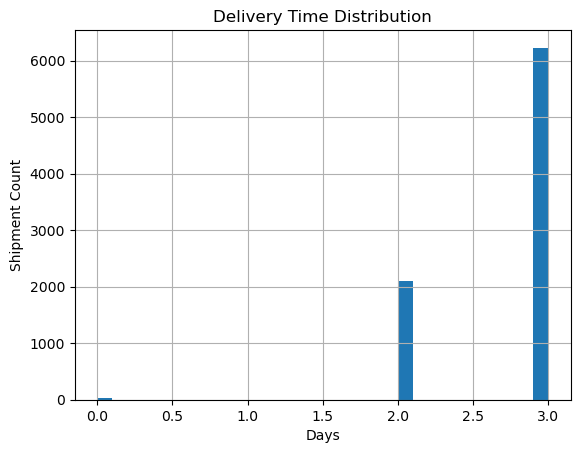

In [12]:
shipment["Delivery_Time_Days"].hist(bins=30)

plt.title("Delivery Time Distribution")
plt.xlabel("Days")
plt.ylabel("Shipment Count")
plt.show()

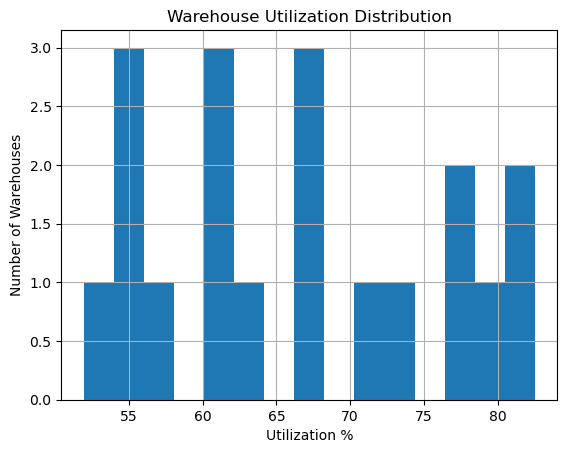

In [13]:
warehouse["Warehouse_Utilization_%"].hist(bins=15)

plt.title("Warehouse Utilization Distribution")
plt.xlabel("Utilization %")
plt.ylabel("Number of Warehouses")
plt.show()

## Bivariate Analysis
Exploring relationships between operational variables.

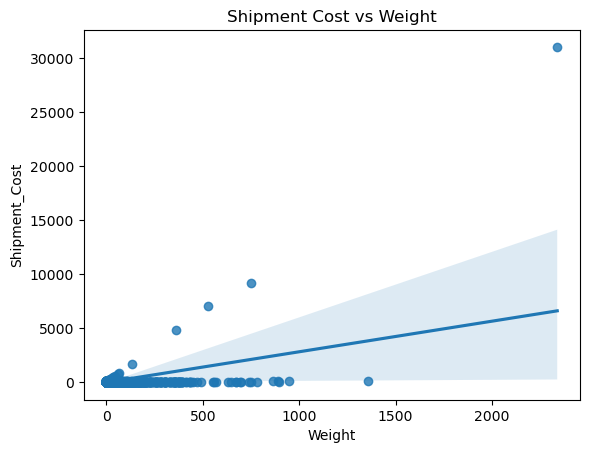

In [14]:
sns.regplot(x="Weight", y="Shipment_Cost", data=shipment)
plt.title("Shipment Cost vs Weight")
plt.show()

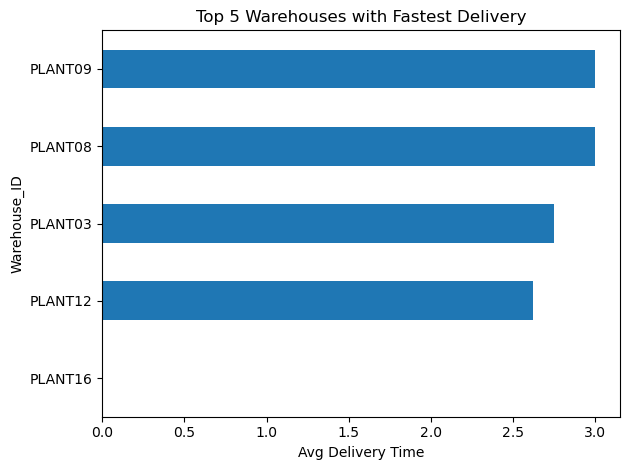

In [15]:
top_wh = shipment.groupby("Warehouse_ID")["Delivery_Time_Days"].mean().sort_values().head(5)

top_wh.plot(kind="barh")
plt.title("Top 5 Warehouses with Fastest Delivery")
plt.xlabel("Avg Delivery Time")
plt.tight_layout()
plt.show()

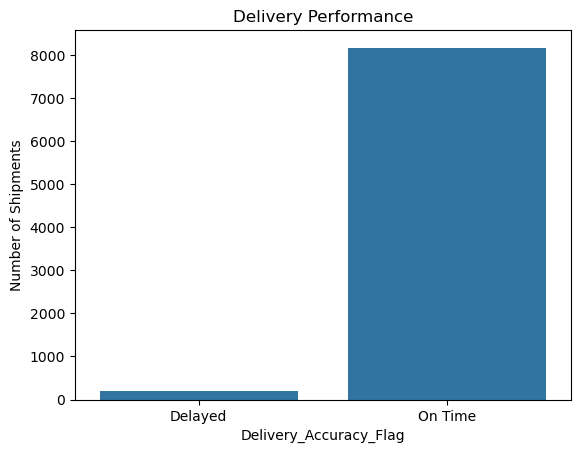

In [16]:
counts = shipment["Delivery_Accuracy_Flag"].value_counts()

sns.barplot(x=counts.index, y=counts.values)
plt.xticks([0,1], ["Delayed", "On Time"])
plt.title("Delivery Performance")
plt.ylabel("Number of Shipments")
plt.show()

## Correlation Analysis
Identifying relationships between numeric logistics variables.

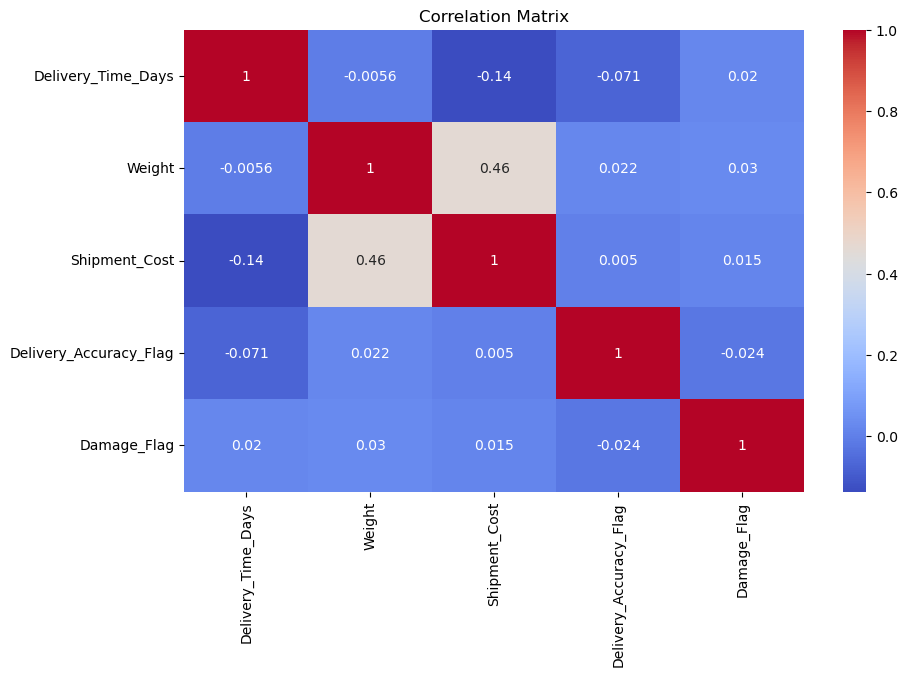

In [17]:
corr = shipment.select_dtypes(include="number").corr()

plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap="coolwarm")

plt.title("Correlation Matrix")
plt.show()

## Business Questions

Based on exploratory analysis, the following logistics questions were identified:

1. Which operational factors contribute to increased delivery delays?
2. How does shipment weight influence shipment cost?
3. Are warehouses operating near maximum utilization?
4. Which operational factors affect delivery performance?
5. Are there patterns in inventory stockouts?

## Hypotheses

H1: Shipment cost increases with shipment weight.

H2: Higher warehouse utilization leads to slower operations.

H3: Longer lead times increase stockout risk.

## Key Insights from EDA

• Average delivery time is approximately 2.8 days, with most shipments delivered within 2–3 days.

• Shipment cost has a moderate positive correlation (0.46) with shipment weight.

• Warehouse utilization averages around 66%, indicating moderate capacity usage.

• Inventory lead time remains constant around 5 days for most products.

• Damage rate is low (~2.6%), indicating efficient handling processes.

• Delivery performance varies slightly across warehouses but remains within a narrow range (2–3 days).

• Warehouse utilization varies across facilities, indicating potential operational differences.

• Inventory lead times may influence stockout patterns.